找到的圖片列表： ['night.jpg', 'CAR.png', 'robot.png']
------------------------------
正在顯示：night.jpg


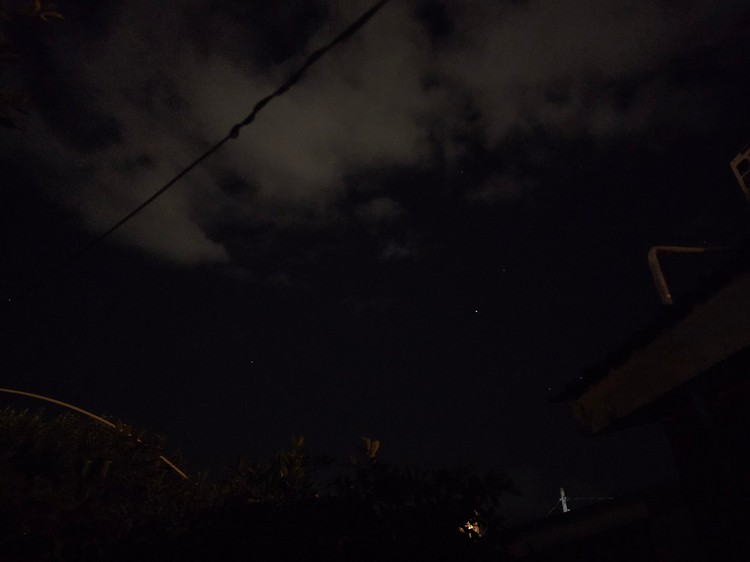

正在顯示：CAR.png


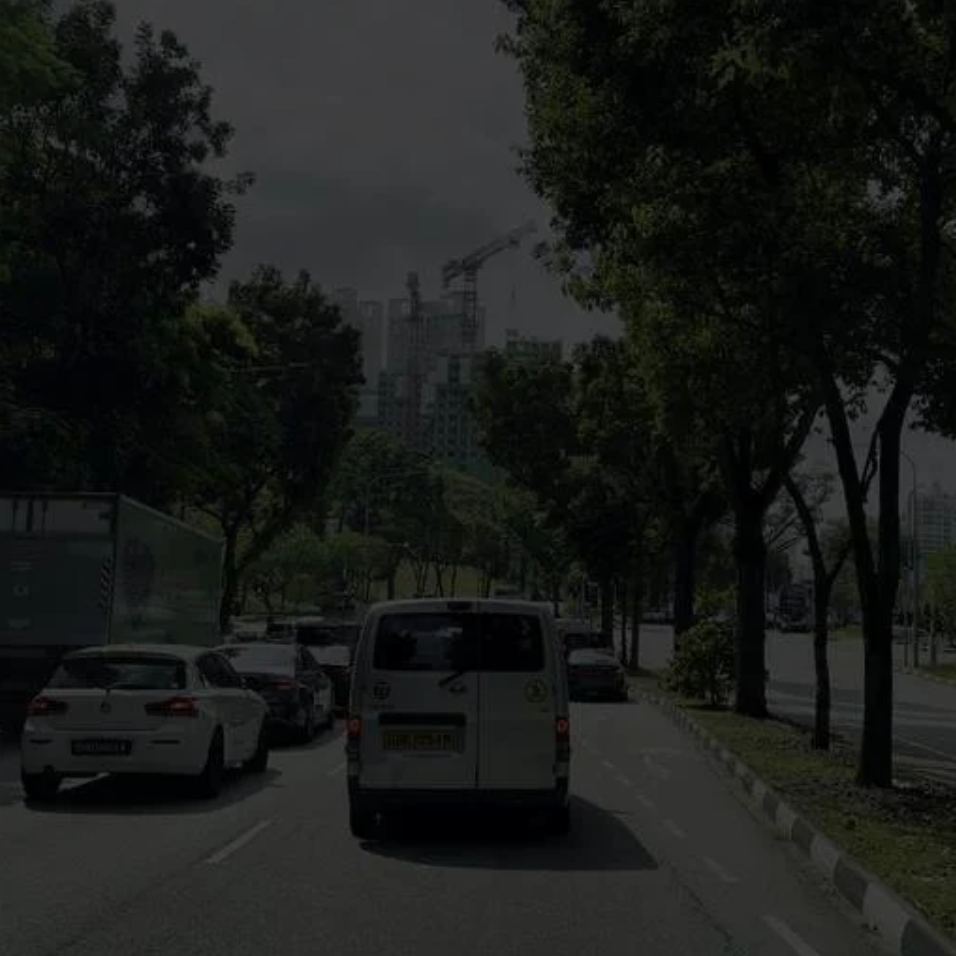

正在顯示：robot.png


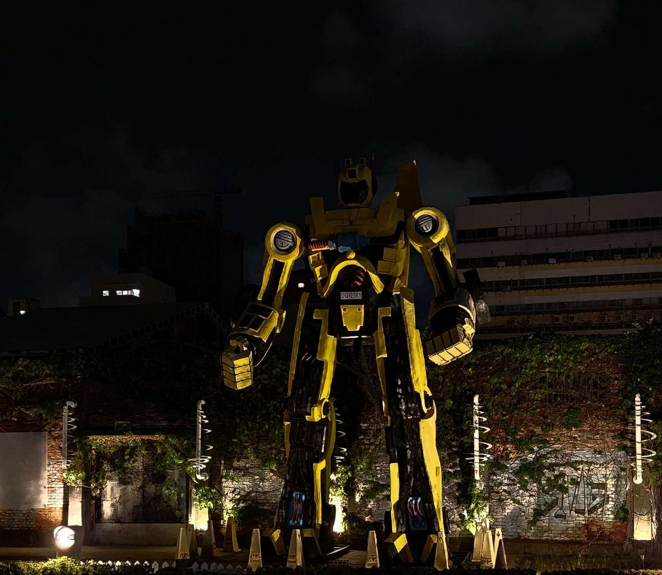

In [2]:
import glob
from IPython.display import Image, display

# 同時尋找當前目錄下的 .jpg 與 .png 檔案
image_files = glob.glob('*.jpg') + glob.glob('*.png')

# 印出找到的檔案清單確認
print("找到的圖片列表：", image_files)
print("-" * 30)

# 使用迴圈逐一顯示圖片
for file in image_files:
    print(f"正在顯示：{file}")
    display(Image(filename=file))

Images in this folder:
  1. CAR.png (757.0 KiB)
  2. night.jpg (32.7 KiB)
  3. robot.png (526.9 KiB)

請選擇要增強的圖片：
  1. CAR.png
  2. night.jpg
  3. robot.png
請輸入圖片編號 (1-3): 3

已選擇: robot.png
正在將選定的圖片裁切成 512x512 並轉換為 Hex 格式...
Converted robot.png -> img_file/robot_512.hex
Notebook folder: /home/xilinx/jupyter_notebooks/final_project
OK: /home/xilinx/jupyter_notebooks/final_project/img_enhance_DDR_wrapper.bit
OK: /home/xilinx/jupyter_notebooks/final_project/img_enhance_DDR_wrapper.hwh
OK: /home/xilinx/jupyter_notebooks/final_project/img_file/robot_512.hex
Loading overlay: /home/xilinx/jupyter_notebooks/final_project/img_enhance_DDR_wrapper.bit
Loading input hex: /home/xilinx/jupyter_notebooks/final_project/img_file/robot_512.hex
Starting DMA, frame bytes = 1048576
FPGA DMA+compute time: 7.589 ms, 131.77 FPS, 34.54 Mpixel/s, 131.77 MiB/s
Saving output hex: /home/xilinx/jupyter_notebooks/final_project/img_file/robot_out.hex
Saving output image: /home/xilinx/jupyter_notebooks/final_project/im

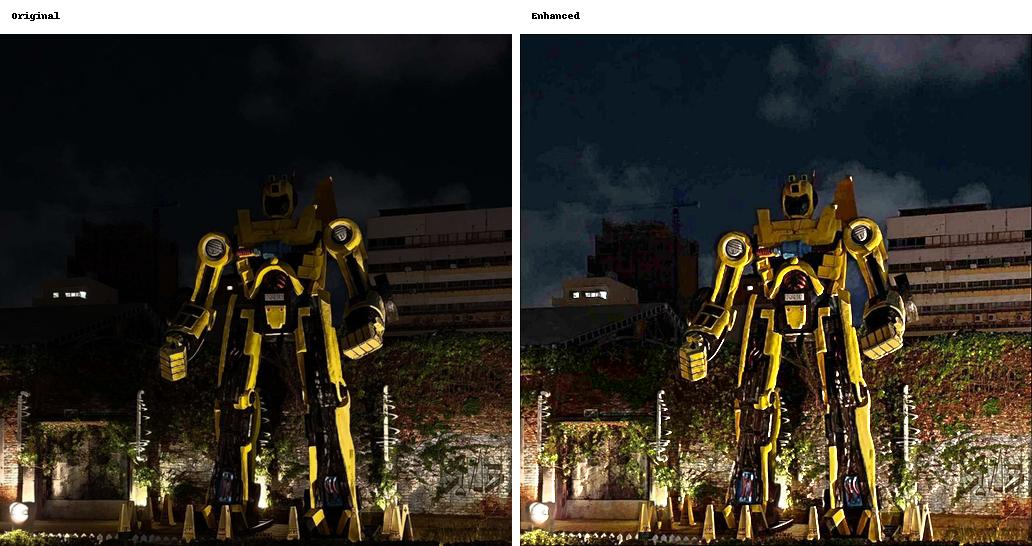

Done. Output checksum = 0xc06f36ba
First pixels: ['020609', '020609', '020609', '020609', '020609', '020609', '020609', '020609']


In [5]:
from pathlib import Path
import time

import numpy as np
from pynq import Overlay, allocate

# Notebook folder on PYNQ. Usually:
# /home/xilinx/jupyter_notebooks/0626
APP_DIR = Path.cwd()

IMG_W = 512
IMG_H = 512
FRAME_PIXELS = IMG_W * IMG_H
BYTES_PER_PIXEL = 4
FRAME_BYTES = FRAME_PIXELS * BYTES_PER_PIXEL
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tif", ".tiff", ".webp"}

bitfile = APP_DIR / "img_enhance_DDR_wrapper.bit"
hwhfile = APP_DIR / "img_enhance_DDR_wrapper.hwh"
dma_name = "axi_dma_0"


def ensure_parent_dir(path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)


def import_pillow():
    try:
        from PIL import Image, ImageDraw, ImageOps
    except ImportError as exc:
        raise RuntimeError("Pillow is required. Install it on PYNQ with: pip3 install pillow") from exc
    return Image, ImageDraw, ImageOps


def list_source_images(directory=APP_DIR):
    """List image files directly under the notebook folder."""
    images = sorted(
        path for path in Path(directory).iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    if not images:
        raise FileNotFoundError(f"No image files found in {directory}")

    print("Images in this folder:")
    for index, image_path in enumerate(images, start=1):
        size_kib = image_path.stat().st_size / 1024
        print(f"  {index}. {image_path.name} ({size_kib:.1f} KiB)")
    return images


def center_crop_resize_rgb(image_path):
    """Center-crop an image to a square, resize it to 512x512, and return an RGB PIL image."""
    Image, _, ImageOps = import_pillow()
    with Image.open(image_path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        width, height = img.size
        side = min(width, height)
        left = (width - side) // 2
        top = (height - side) // 2
        cropped = img.crop((left, top, left + side, top + side))
        resampling = getattr(getattr(Image, "Resampling", Image), "LANCZOS", Image.BICUBIC)
        return cropped.resize((IMG_W, IMG_H), resampling)


def rgb_image_to_words(image):
    """Convert a 512x512 RGB PIL image to uint32 0x00RRGGBB words."""
    pixels = np.asarray(image, dtype=np.uint8).reshape(-1, 3).astype(np.uint32)
    return (pixels[:, 0] << 16) | (pixels[:, 1] << 8) | pixels[:, 2]


def image_hex_path(image_path):
    return APP_DIR / "img_file" / f"{Path(image_path).stem}_512.hex"


def convert_image_to_hex(image_path):
    """Crop/resize one image to 512x512 and save one RRGGBB pixel per line."""
    image_path = Path(image_path)
    output_path = image_hex_path(image_path)
    ensure_parent_dir(output_path)

    rgb_image = center_crop_resize_rgb(image_path)
    words = rgb_image_to_words(rgb_image)
    save_rgb_hex(output_path, words)
    print(f"Converted {image_path.name} -> {output_path.relative_to(APP_DIR)}")
    return output_path


def choose_and_prepare_image():
    """先讓使用者選擇圖片，再針對『被選中』的圖片進行 512x512 裁切與轉檔。"""
    images = list_source_images(APP_DIR)
    
    print("\n請選擇要增強的圖片：")
    for index, img_path in enumerate(images, start=1):
        print(f"  {index}. {img_path.name}")

    while True:
        raw = input(f"請輸入圖片編號 (1-{len(images)}): ").strip()
        try:
            choice = int(raw)
        except ValueError:
            print("格式錯誤，請輸入數字。")
            continue
            
        if 1 <= choice <= len(images):
            selected_path = images[choice - 1]
            print(f"\n已選擇: {selected_path.name}")
            break
        print(f"請輸入 1 到 {len(images)} 之間的有效數字。")

    print("正在將選定的圖片裁切成 512x512 並轉換為 Hex 格式...")
    hex_path = convert_image_to_hex(selected_path)

    return {"image_path": selected_path, "hex_path": hex_path}


def load_rgb_hex(path):
    """Load one RRGGBB pixel per line into 0x00RRGGBB uint32 words."""
    path = Path(path)
    words = np.empty(FRAME_PIXELS, dtype=np.uint32)
    count = 0

    with path.open("r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if count >= FRAME_PIXELS:
                raise ValueError(f"{path} has more than {FRAME_PIXELS} pixels")
            words[count] = int(line, 16) & 0x00FFFFFF
            count += 1

    if count != FRAME_PIXELS:
        raise ValueError(f"{path} has {count} pixels, expected {FRAME_PIXELS}")
    return words


def save_rgb_hex(path, words):
    """Save uint32 words as one 24-bit RRGGBB pixel per line."""
    path = Path(path)
    ensure_parent_dir(path)
    flat = np.asarray(words, dtype=np.uint32).reshape(-1)
    if flat.size != FRAME_PIXELS:
        raise ValueError(f"output has {flat.size} pixels, expected {FRAME_PIXELS}")
    with path.open("w") as f:
        for value in flat:
            f.write(f"{int(value) & 0x00FFFFFF:06x}\n")


def words_to_rgb_array(words):
    """Convert uint32 0x00RRGGBB words to a H x W x RGB uint8 image array."""
    flat = np.asarray(words, dtype=np.uint32).reshape(-1)
    if flat.size != FRAME_PIXELS:
        raise ValueError(f"image has {flat.size} pixels, expected {FRAME_PIXELS}")

    pixels = flat & 0x00FFFFFF
    img_array = np.empty((FRAME_PIXELS, 3), dtype=np.uint8)
    img_array[:, 0] = (pixels >> 16) & 0xFF
    img_array[:, 1] = (pixels >> 8) & 0xFF
    img_array[:, 2] = pixels & 0xFF
    return img_array.reshape((IMG_H, IMG_W, 3))


def save_rgb_image(path, words):
    """Save uint32 0x00RRGGBB words as an RGB image."""
    Image, _, _ = import_pillow()
    path = Path(path)
    ensure_parent_dir(path)
    Image.fromarray(words_to_rgb_array(words), "RGB").save(path)


def save_comparison_image(path, input_words, output_words):
    """Save a side-by-side original/enhanced image for visual comparison."""
    Image, ImageDraw, _ = import_pillow()
    path = Path(path)
    ensure_parent_dir(path)

    input_img = Image.fromarray(words_to_rgb_array(input_words), "RGB")
    output_img = Image.fromarray(words_to_rgb_array(output_words), "RGB")

    label_h = 34
    gap = 8
    canvas_w = (IMG_W * 2) + gap
    canvas_h = IMG_H + label_h
    canvas = Image.new("RGB", (canvas_w, canvas_h), "white")
    canvas.paste(input_img, (0, label_h))
    canvas.paste(output_img, (IMG_W + gap, label_h))

    draw = ImageDraw.Draw(canvas)
    draw.text((12, 10), "Original", fill=(0, 0, 0))
    draw.text((IMG_W + gap + 12, 10), "Enhanced", fill=(0, 0, 0))
    canvas.save(path)


def display_image(path):
    """Display an image inline inside Jupyter."""
    try:
        from IPython.display import Image as NotebookImage
        from IPython.display import display
    except ImportError:
        print(f"Open the saved image file to view the result: {path}")
        return
    display(NotebookImage(filename=str(path)))


def find_dma(overlay, preferred_name="axi_dma_0"):
    if hasattr(overlay, preferred_name):
        return getattr(overlay, preferred_name)

    dma_names = [
        name for name, info in overlay.ip_dict.items()
        if "axi_dma" in info.get("type", "")
    ]
    if not dma_names:
        raise RuntimeError("No AXI DMA found in overlay.ip_dict")
    print(f"Using DMA instance: {dma_names[0]}")
    return getattr(overlay, dma_names[0])


def check_dma_length(dma):
    max_size = getattr(dma.sendchannel, "_max_size", None)
    if max_size is not None and FRAME_BYTES > max_size:
        raise RuntimeError(
            f"DMA max transfer is {max_size} bytes, but frame is {FRAME_BYTES} bytes. "
            "In Vivado AXI DMA, increase Width of Buffer Length Register."
        )


def check_required_files(input_hex):
    print(f"Notebook folder: {APP_DIR}")
    for path in [bitfile, hwhfile, input_hex]:
        state = "OK" if path.exists() else "MISSING"
        print(f"{state}: {path}")

    if not bitfile.exists():
        raise FileNotFoundError(f"bitfile not found: {bitfile}")
    if not hwhfile.exists():
        raise FileNotFoundError(f"hwh file not found: {hwhfile}")
    if not input_hex.exists():
        raise FileNotFoundError(f"input hex not found: {input_hex}")


def run_dma(selected, display_result=True):
    input_hex = selected["hex_path"]
    selected_stem = selected["image_path"].stem
    output_hex = APP_DIR / "img_file" / f"{selected_stem}_out.hex"
    output_image = APP_DIR / "img_file" / f"{selected_stem}_out.jpg"
    comparison_image = APP_DIR / "img_file" / f"{selected_stem}_out_compare.jpg"

    check_required_files(input_hex)

    print(f"Loading overlay: {bitfile}")
    overlay = Overlay(str(bitfile))
    dma = find_dma(overlay, dma_name)
    check_dma_length(dma)

    print(f"Loading input hex: {input_hex}")
    input_words = load_rgb_hex(input_hex)

    in_buf = allocate(shape=(FRAME_PIXELS,), dtype=np.uint32)
    out_buf = allocate(shape=(FRAME_PIXELS,), dtype=np.uint32)

    try:
        in_buf[:] = input_words
        out_buf[:] = 0
        in_buf.flush()
        out_buf.flush()

        print(f"Starting DMA, frame bytes = {FRAME_BYTES}")
        dma_start = time.perf_counter()
        dma.recvchannel.transfer(out_buf)
        dma.sendchannel.transfer(in_buf)
        dma.sendchannel.wait()
        dma.recvchannel.wait()
        dma_elapsed = time.perf_counter() - dma_start
        out_buf.invalidate()

        frame_mib = FRAME_BYTES / (1024 * 1024)
        fps = 1.0 / dma_elapsed
        mpixels_per_sec = FRAME_PIXELS / dma_elapsed / 1_000_000
        mib_per_sec = frame_mib / dma_elapsed
        print(
            "FPGA DMA+compute time: "
            f"{dma_elapsed * 1000:.3f} ms, "
            f"{fps:.2f} FPS, "
            f"{mpixels_per_sec:.2f} Mpixel/s, "
            f"{mib_per_sec:.2f} MiB/s"
        )

        print(f"Saving output hex: {output_hex}")
        save_rgb_hex(output_hex, out_buf)
        print(f"Saving output image: {output_image}")
        save_rgb_image(output_image, out_buf)
        print(f"Saving comparison image: {comparison_image}")
        save_comparison_image(comparison_image, input_words, out_buf)

        if display_result:
            display_image(comparison_image)

        checksum = int(np.sum(np.asarray(out_buf, dtype=np.uint32) & 0x00FFFFFF) & 0xFFFFFFFF)
        print(f"Done. Output checksum = 0x{checksum:08x}")
        print("First pixels:", [f"{int(x) & 0x00FFFFFF:06x}" for x in out_buf[:8]])
    finally:
        in_buf.freebuffer()
        out_buf.freebuffer()


# ==========================================
# 程式進入點
# ==========================================
selected_image = choose_and_prepare_image()
run_dma(selected_image, display_result=True)